# Figure 5B

In [1]:
from riskhistory.format import rcParams
from riskhistory.data import (
    load_pupiltimeseries_avgpred,
    load_pupiltimeseries_avgpred_choice,
    load_pupilbetas_transition_contrasts,
    load_pupilbetas_transition_contrast_choice,
    load_replicate_acceptmodel_fixed_effects,
    DATASET_LABELS,
)
import matplotlib.pyplot as plt

DATASETS = ["equalIndifference", "equalRange", "sheng2020"]

### Helper functions

In [2]:
# ----- Pupil timeseries by current choice -----
# accept = mean of A-A and R-A, reject = mean of R-R and A-R (equal weights)
CHOICE_LABELS = {
    "accept": "Accept trials (A)",
    "reject": "Reject trials (R)",
}
CHOICE_COLORS = {
    "accept": "#ff4b2b",
    "reject": "#468bf2",
}


def plot_choice_timeseries_panel(ax, ds_avgpred, dataset, show_ylabel=False,
                                 show_dataset_label=False, show_xlabel=False):
    """Adjusted pupil size over time for accept vs. reject trials."""
    for choice, label in CHOICE_LABELS.items():
        choice_emm = ds_avgpred[ds_avgpred["choice"] == choice].sort_values("timebin")
        color = CHOICE_COLORS[choice]
        ax.plot(choice_emm["timebin"], choice_emm["avgpred"], color=color,
                linewidth=8, label=label)
        ax.fill_between(choice_emm["timebin"], choice_emm["asymp.LCL"],
                        choice_emm["asymp.UCL"], color=color, alpha=0.15)

    ax.axhline(0, color="#aaaaaa", linewidth=2, linestyle="--", zorder=1)
    ax.set_ylim(-0.6, 0.8)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.legend(loc="upper left", frameon=True)
    if show_ylabel:
        ax.set_ylabel("Mean pupil size")
    else:
        ax.set_ylabel("\n")
    if show_dataset_label:
        ax.set_title(f"{DATASET_LABELS[dataset]}", va="top")
    if show_xlabel:
        ax.set_xlabel("Time since start of the trial (sec)", loc="left")


# ----- Transition figure: pupil timeseries by transition -----
# AA/AR/RA/RR = (previous choice, current choice)
TRANSITION_SHORT = {
    "accept_to_accept": "A-A (repeat)",
    "accept_to_reject": "A-R (switch)",
    "reject_to_accept": "R-A (switch)",
    "reject_to_reject": "R-R (repeat)",
}
TRANSITION_COLORS = {
    "accept_to_accept": "#8C0000",
    "accept_to_reject": "#008C59",
    "reject_to_accept": "#DCC200",
    "reject_to_reject": "#291B85",
}
# One panel per (current choice, pair of transitions compared)
TRANSITION_PANELS = [
    ("Accept trials", ("reject_to_accept", "accept_to_accept")),
    ("Reject trials", ("accept_to_reject", "reject_to_reject")),
]


def plot_transition_timeseries_panel(ax, ds_avgpred, transitions, title,
                                     show_ylabel=False):
    """Adjusted pupil size over time for two transition levels."""
    for level in transitions:
        level_emm = ds_avgpred[ds_avgpred["transition"] == level].sort_values("timebin")
        color = TRANSITION_COLORS[level]
        ax.plot(level_emm["timebin"], level_emm["avgpred"], color=color,
                linewidth=8, label=TRANSITION_SHORT[level])
        ax.fill_between(level_emm["timebin"], level_emm["asymp.LCL"],
                        level_emm["asymp.UCL"], color=color, alpha=0.15)

    ax.axhline(0, color="#aaaaaa", linewidth=2, linestyle="--", zorder=1)
    ax.set_ylim(-0.6, 0.8)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.legend(loc="upper left", frameon=True)
    ax.set_title(title)
    if show_ylabel:
        ax.set_ylabel("Mean pupil size", fontsize=plt.rcParams["axes.labelsize"]*1.3)
    else:
        if title == "Accept trials":
            ax.set_ylabel("\n\n")


# ----- Scatter: acceptance bias vs. pupil contrasts -----
P_COLUMN = "p.value"  # or "p_adj_bh" (BH across the 6 pairwise contrasts per dataset)


def p_stars(p):
    if p < 0.001:
        return "***"
    if p < 0.01:
        return "**"
    if p < 0.05:
        return "*"
    return "n.s."


def annotate_stars(ax, x, y_top, p):
    ax.annotate(p_stars(p), xy=(x, y_top), xytext=(0, 4), textcoords="offset points",
                ha="center", va="bottom", fontsize=18, fontweight="bold")


def get_transition_contrast(ds_contrasts, label_a, label_b):
    """Estimate, SE and p for label_a - label_b (sign flipped if stored as b - a)."""
    for contrast, sign in ((f"{label_a} - {label_b}", 1), (f"{label_b} - {label_a}", -1)):
        match = ds_contrasts[ds_contrasts["contrast"] == contrast]
        if len(match):
            row = match.iloc[0]
            return sign * row["estimate"], row["SE"], row[P_COLUMN]
    raise KeyError(f"No contrast found for {label_a} vs {label_b}")


def plot_bias_scatter(ax, intercepts, pupil_contrasts, ylabel, color):
    """x: replicate_baseline intercept (95% CI); y: pupil contrast (± 1.96 SE).
    pupil_contrasts maps dataset -> (estimate, SE, p)."""
    ax.axvline(0, color="#aaaaaa", linewidth=2, linestyle="--", zorder=1)
    ax.axhline(0, color="#aaaaaa", linewidth=2, linestyle="--", zorder=1)
    for ds in DATASETS:
        x = intercepts.loc[ds]
        estimate, se, p = pupil_contrasts[ds]
        y_half_ci = 1.96 * se
        ax.errorbar(x["estimate"], estimate,
                    xerr=[[x["estimate"] - x["conf.low"]], [x["conf.high"] - x["estimate"]]],
                    yerr=y_half_ci, fmt="o", color=color, markersize=24,
                    elinewidth=3, capsize=8, zorder=3)
        annotate_stars(ax, x["estimate"], estimate + y_half_ci, p)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.set_xlabel("Response tendency (log-odds)", fontsize = plt.rcParams["axes.labelsize"]*1.4)
    ax.set_ylabel(f"Mean ∆ Decision-related pupil\n{ylabel}", fontsize = plt.rcParams["axes.labelsize"]*1.4)
    ax.set_ylim(-0.4, 0.4)
    ax.set_xlim(-7, 7)

### 1 x 3 figure: pupil timeseries by current choice
Predicted pupil size over time (start-aligned) for accept vs. reject trials, each the equal-weight mean of its two transitions (accept = A-A, R-A; reject = R-R, A-R). One panel per dataset.

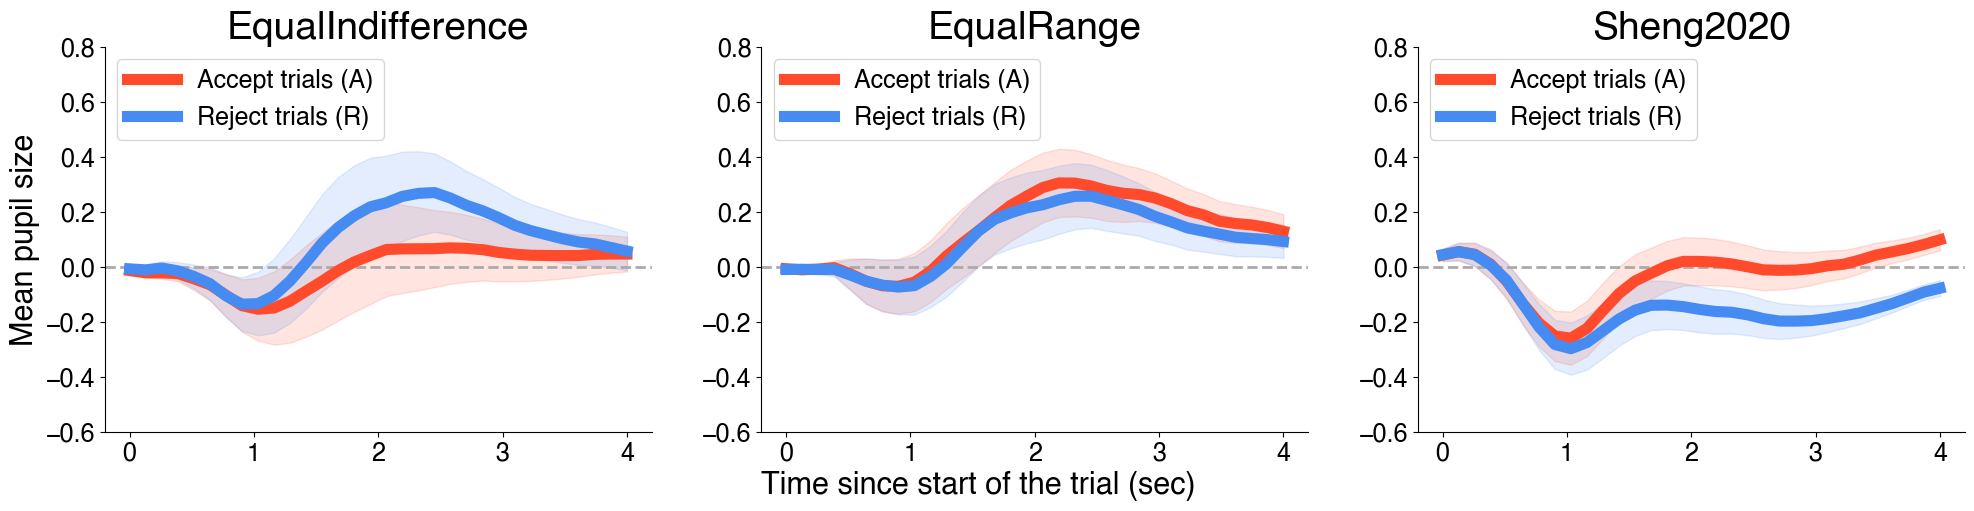

In [3]:
avgpred_choice_start = load_pupiltimeseries_avgpred_choice(alignment="start")

fig, axes = plt.subplots(nrows=1, ncols=len(DATASETS), figsize=(24, 5))
for ds_idx, ds in enumerate(DATASETS):
    ds_avgpred = avgpred_choice_start[avgpred_choice_start["dataset"] == ds]
    plot_choice_timeseries_panel(
        axes[ds_idx], ds_avgpred, ds,
        show_ylabel=(ds_idx == 0),
        show_dataset_label=True,
        show_xlabel=(ds_idx == 1),
    )

fig.savefig("saved/figure5_B_choice.svg", dpi=300, bbox_inches="tight")
plt.show()

### 1 x 6 figure: pupil timeseries by transition
Predicted pupil size over time (response-aligned), two panels per dataset: accept trials (R-A vs A-A) and reject trials (A-R vs R-R).

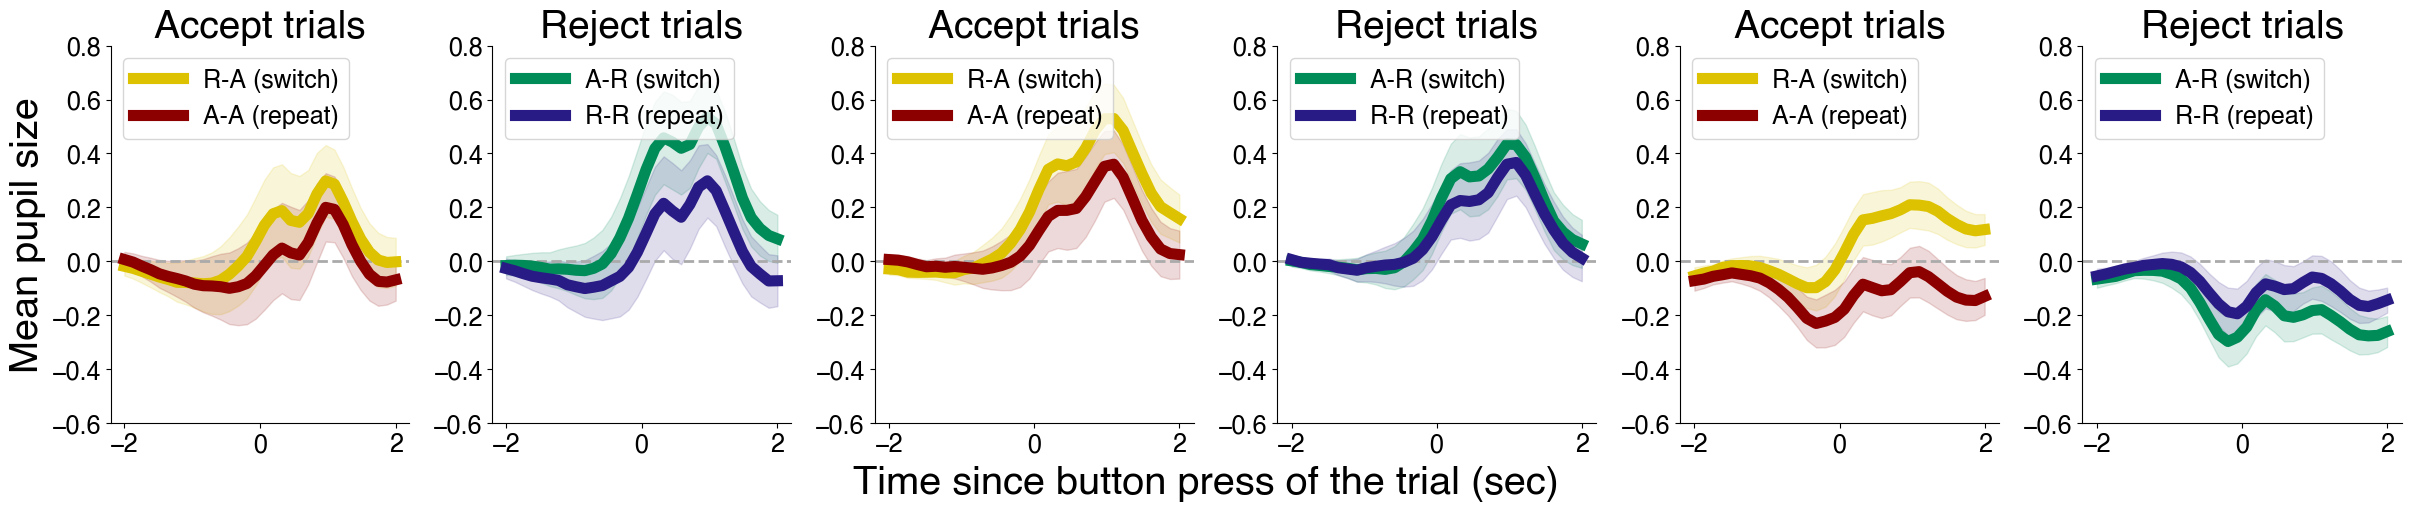

In [4]:
avgpred_response = load_pupiltimeseries_avgpred(alignment="response")

fig = plt.figure(figsize=(24, 5), layout="constrained")
subfigs = fig.subfigures(nrows=1, ncols=len(DATASETS))

# --- One pair of panels per dataset: accept trials, reject trials ---
for ds_idx, (subfig, ds) in enumerate(zip(subfigs, DATASETS)):
    ds_avgpred = avgpred_response[avgpred_response["dataset"] == ds]
    axes = subfig.subplots(nrows=1, ncols=len(TRANSITION_PANELS))
    for panel_idx, (title, transitions) in enumerate(TRANSITION_PANELS):
        plot_transition_timeseries_panel(
            axes[panel_idx], ds_avgpred, transitions, title,
            show_ylabel=(ds_idx == 0 and panel_idx == 0),
        )

fig.supxlabel("Time since button press of the trial (sec)",
              fontsize=plt.rcParams["axes.labelsize"]*1.3)

fig.savefig("saved/figure5_B_transitions.svg", dpi=300, bbox_inches="tight")
plt.show()

### 1 x 3 figure: acceptance bias vs. pupil contrasts
x: intercept of the replicate baseline accept model (95% CI); y: pupil-beta contrast (95% CI = estimate ± 1.96 SE, stars = p), one point per dataset. Panels: accept − reject (purple), reject-trial switch − repeat A-R − R-R (blue), accept-trial switch − repeat R-A − A-A (red).

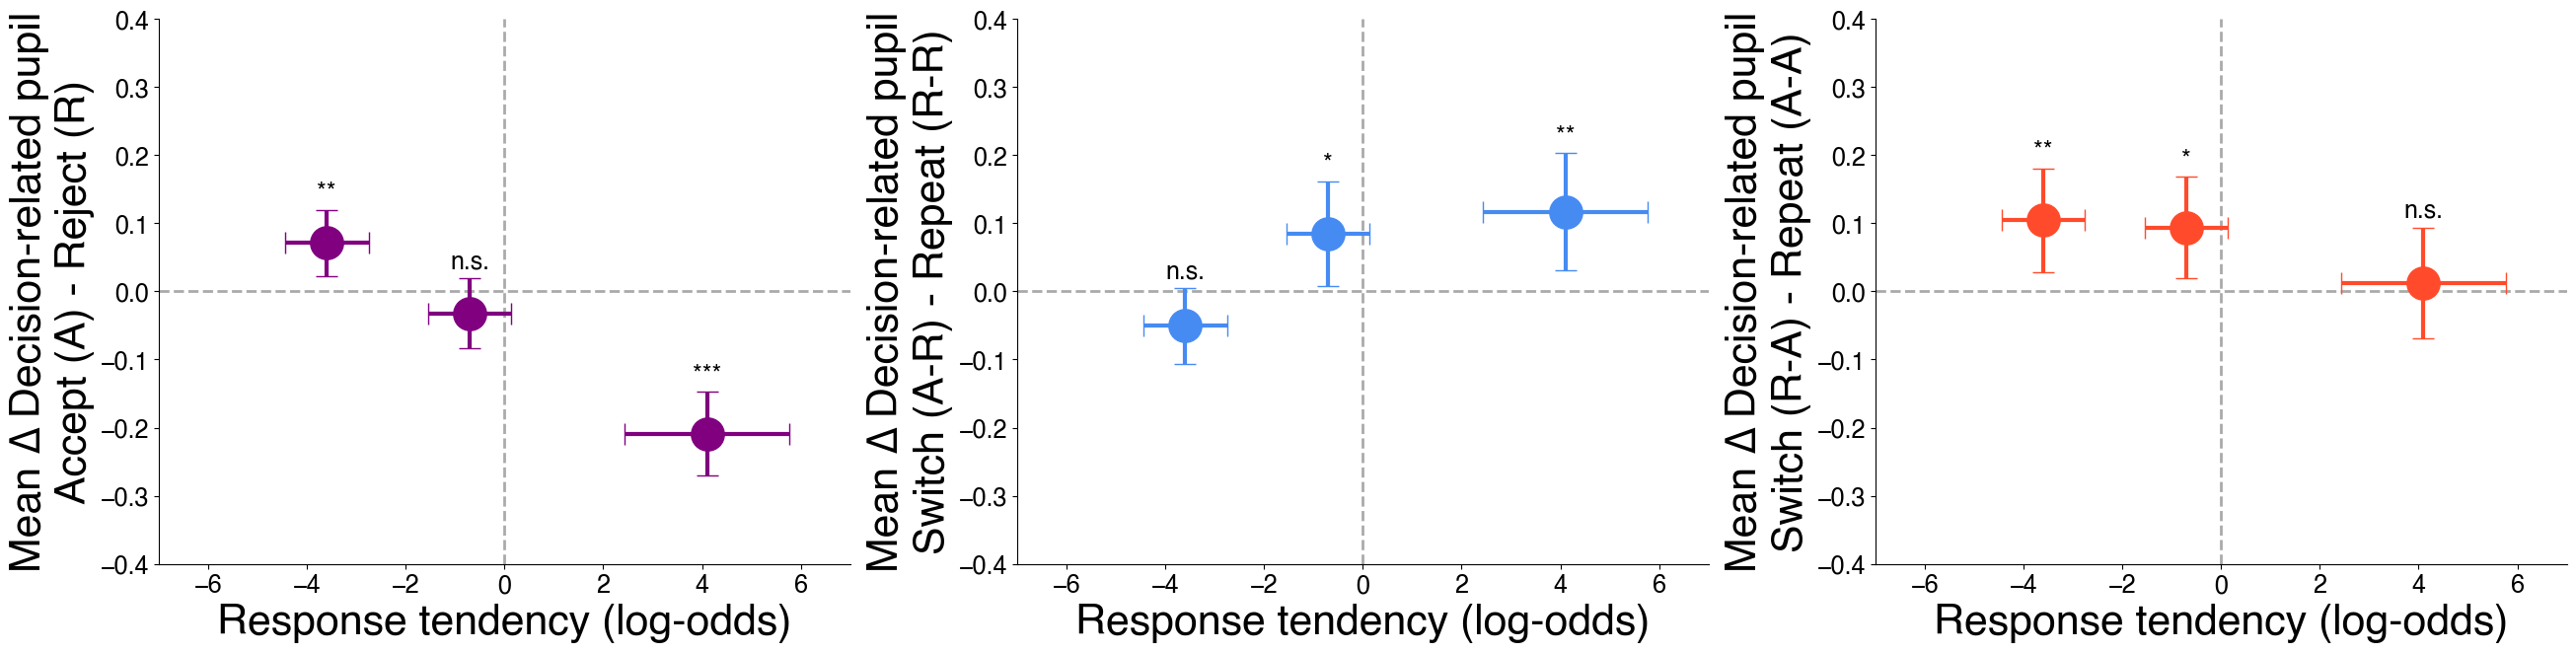

In [5]:
intercepts = (load_replicate_acceptmodel_fixed_effects()
              .query("model == 'replicate_baseline' and term == '(Intercept)'")
              .set_index("dataset"))
choice_contrast = load_pupilbetas_transition_contrast_choice().set_index("dataset")
transition_contrasts = load_pupilbetas_transition_contrasts()


def switch_contrasts(switch, repeat):
    return {ds: get_transition_contrast(transition_contrasts[transition_contrasts["dataset"] == ds],
                                        switch, repeat)
            for ds in DATASETS}


# (pupil contrast per dataset, y-label, color) -- one panel each
PANELS = [
    ({ds: tuple(choice_contrast.loc[ds, ["estimate", "SE", "p.value"]]) for ds in DATASETS},
     "Accept (A) - Reject (R)", "purple"),
    (switch_contrasts("accept_to_reject", "reject_to_reject"),
     "Switch (A-R) - Repeat (R-R)", "#468bf2"),
    (switch_contrasts("reject_to_accept", "accept_to_accept"),
     "Switch (R-A) - Repeat (A-A)", "#ff4b2b"),
]

fig, axes = plt.subplots(nrows=1, ncols=len(PANELS), figsize=(26, 6.5), layout="constrained")
for ax, (pupil_contrasts, ylabel, color) in zip(axes, PANELS):
    plot_bias_scatter(ax, intercepts, pupil_contrasts, ylabel, color)

fig.savefig("saved/figure4_B_v2_bias_scatters.svg", dpi=300, bbox_inches="tight")
plt.show()